In [23]:
%config InlineBackend.figure_formats = ['svg']
import matplotlib.pyplot as plt
plt.ioff()

## Introduction
As mentioned in the presentation: particle generation (event generation) is the first step within particle physics simulations.

We'll use our knowledge of physics processes to inform our design of an event generator. 

Phlex allows users to write _algorithms_ in c++ or python. We can write a simple function representing our event generator and then plug it into phlex.

MAKE A NOTE ABOUT HOW WE HAVE TO MAKE SURE THAT THE RESULTS OF THIS PART OF THE SIMULATION ARE FORWARDED INTO LATER PARTS



With a little bit of python we can simulate neutrino interactions! (As long as we keep things simple)

One of the simplest neutrino interactions is the CCQE interaction on a free, at-rest neutron: $\nu_l + n \rightarrow \mu^- + p$

Let's assume we have a neutrino with energy 1 GeV/c strike an at-rest neutron traveling in the $\hat{z}$ direction. For a given choice of the outgoing muon's angle $\theta_\mu$, we can determine the energy of the muon $E_\mu$, the energy of the proton $E_p$, and the direction of the proton $\theta_p$:

<img src="img/ccqe_interaction.png" style="background-color: white; padding: 10px;" />


In [24]:
import math

# We'll use units of GeV for energy & momentum
# and degrees for angles

#Masses
mn = 0.939565
mp = 0.938272
mmu = 0.105658

def ccqe_kinematics(theta_mu, enu=1.0):
    thetamu = math.radians(theta_mu)

    # Derivation left as an exercise for the reader :) 
    a = 2.0 * enu * math.cos(thetamu)
    b = 2.0 * (enu + mn)
    c = mn * mn - mp * mp + mmu * mmu + 2.0 * enu * mn
    d = b * b - a * a
    emu = (b * c + a * math.sqrt(c * c - mmu * mmu * d)) / d

    pmu = math.sqrt(emu * emu - mmu * mmu)
    pmu_z = math.cos(thetamu) * pmu
    pmu_t = math.sin(thetamu) * pmu #Transverse momentum -- define this to be x-direction below

    # enu == pnu == p_proton + p_muon
    pp_z = enu - pmu_z
    ep = math.sqrt(pp_z*pp_z + pmu_t*pmu_t + mp*mp) # E = srqt(m^2 + p^2) w/ transverse momentum balance |pp_t| = |pmu_t|
    return {
        'muon': (pmu_t, 0, pmu_z, emu), # Muon 4-momentum
        'proton': (-pmu_t, 0, pp_z, ep) # Proton 4-momentum
    }

    

In [25]:
results = ccqe_kinematics(45, 1.0)

In [26]:
# Check: total energy conservation
1.0 + mn == results['muon'][-1] + results['proton'][-1] # index -1 is energy

True

In [27]:
# Check: momentum conservation x
0 == results['muon'][0] + results['proton'][0] # index 0 is px

True

In [28]:
# Check: momentum conservation y -- no momentum
results['muon'][1] == -results['proton'][1] # index 1 is py

True

In [29]:
# index 2 is pz -- should equal the neutrino momentum (==energy)
results['muon'][2] + results['proton'][2] == 1.0 

True

In [30]:
emus, eps, theta_ps, theta_mus = [], [], [], []
for i in range(0,181):
    results = ccqe_kinematics(i)
    emus.append(results['muon'][-1])
    eps.append(results['proton'][-1])
    theta_ps.append(math.degrees(math.atan(results['proton'][1]/results['proton'][2])))
    theta_mus.append(i)
    

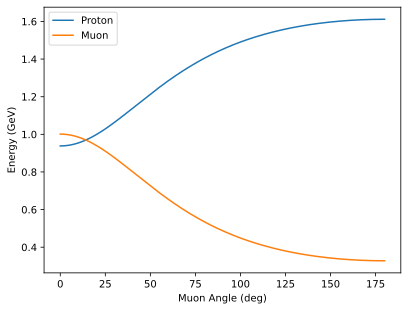

In [31]:
plt.plot(theta_mus, eps, label='Proton')
plt.plot(theta_mus, emus, label='Muon')
plt.ylabel('Energy (GeV)')
plt.xlabel('Muon Angle (deg)')
plt.legend()
plt.show()

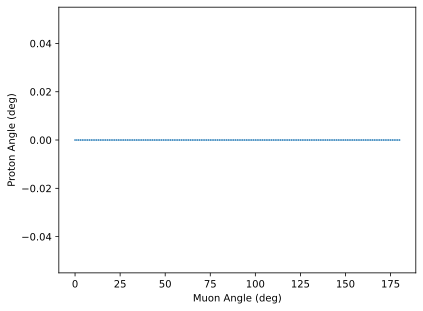

In [32]:
plt.scatter(theta_mus, theta_ps, s=0.5)
plt.ylabel('Proton Angle (deg)')
plt.xlabel('Muon Angle (deg)')
plt.show()

We've successfully modeled CCQE neutrino interactions! Now let's understand how we might fit this into phlex

## Data structures
Phlex controls series of *operators* orchestrated by *higher-order-functions*. The operators might have specific requirements on the type of data being operated upon. For example, let's say we want to calibrate the energy in a "hit" seen in the LArTPC. That operation might amount to a simple process like `E_calibrated = C * E`. We know that `E` is a number that represents the energy in the hit and `C` is a number that represents the calibration factor. However, it's important to make sure that our code is properly representing the numbers for the operations we want to run. For example, in python we can't multiply 2 strings together.

In [33]:
E='2 MeV'
C='one and two-thirds'
print(type(E), type(C))
try:
    print(C*E)
except TypeError: ## If the above doesn't work, let us know
    print("That didn't work")

<class 'str'> <class 'str'>
That didn't work


Q: What does this (admittedly simple) example teach us?

A: We need to represent our data in ways that our code can use it! The energy of a hit might literally be "2 MeV" and we might want to sacle it by 5/3: but our code needs to understand that.

Let's return to the kinematics calculation above:
```
    return {
        'muon': (0, pmu_t, pmu_z, emu), # Muon 4-momentum
        'proton': (0, -pmu_t, pp_z, ep) # Proton 4-momentum
    }

```

While this might represent our physics correctly, we have to consider how the other code we work with needs to use it. 

## HepMC3
Later on in the examples, we'll make use of a series of classes from [HepMC3](https://gitlab.cern.ch/hepmc/HepMC3) to represent physics interactions, particles, etc. The data is organized in several classes:

### HepMC::GenParticle
This represents a particle described by several attributes
 - Its PDG Code (i.e. muon: 13, proton: 2212)
 - Its 4-momentum
 - Its mass (on- or off-shell)
 - Its 'status' (metadata -- for this example, everything will have status=1)

### HepMC::GenVertex
This is the 'site' of some process or interaction and is described by
 - Its location in space and time
 - The particles (GenParticles) entering the vertex (optional)
 - The particles exiting the vertex

In our example CCQE interaction above ($\nu + n \rightarrow p + \mu^-$): $\nu$ and $n$ enter the vertex, while $\mu^-$ and $p$ exit it.

Note: we never chose a position or time within the interaction we described above so we'll have to decide where to put that as we build up into Phlex

### HepMC::GenEvent
In DUNE, 'Event' doesn't mean as much as it does in collider experiments/simulation, so I won't focus on this too much. For now: it's just a collection of vertices that we want to consider together. They might be grouped together for multiple reasons: i.e. they are a series of radiological decays within a readout window in the DUNE Far Detector which we are using for testing calibrations in simulation. 


### Consider our interaction
In our simple example above, we would have
 - GenEvent: 1 encompassing our 'simulation'
     - GenVertex: 1 encompassing our interaction
         - GenParticle (consider outgoing/exiting only): 2 -- the muon and the proton

## Slight Roadblock: What can we currently do in Phlex with python?
Currently, Phlex can only pass some simple python objects between nodes i.e. individual numbers and 1D numeric arrays.

For now, we have to work around this, but I've got some tools to help:
1. `GenEventTable`: A class which exposes a structure like the HepMC classes above to the user, but which produces a 1D array to pass out of the python node
2. A c++ node that reads the serialized 1D array and converts back into the structured HepMC classes

`GenEventTable` has 3 methods that we'll work with:
1. `add_vertex(x, y, z, t=0.0) -> int`: Create a new vertex in the event at position `(x, y, z)` at time `t` (default=0). Returns the index of the vertex in the event.
2. `add_particle(i, pdg, status, 4-momentum, mass)`: Create a new particle exiting the vertex at index `i`, with the corresponding attributes. No return
3. `to_array()`: Translates the structured event into a 1D array

### Integrating our generator
Now, can take the `ccqe_kinematics` function we defined above and start to create the correct data structure we can pass through Phlex. Below, we wrap our generate function in another function that 
1. Takes in an event number and a list of vertex positions, as well as a single muon angle
2. It uses our `ccqe_kinematics` function to generate a muon and proton at each vertex position.
3. It adds those particles to the structured event table
4. It returns the serialized event table

In [34]:
# 
import os
import sys

# Compute or hardcode the absolute path to your modules
module_path = os.path.abspath(os.path.join(os.getcwd())) 

if module_path not in sys.path:
    sys.path.insert(0, module_path)


In [35]:
import numpy as np
import numpy.typing as npt
from genevent_table import GenEventTable
def generate(
    event_number: int, positions: list[tuple[float, float, float]], muon_angle: float
) -> npt.NDArray[np.float64]:
    """Build an event with one CCQE interaction at each vertex position.

    Args:
        event_number (int): Event number stored in the table.
        positions (list): Vertex positions (x, y, z) in cm.
        muon_angle (float): Muon angle to the neutrino direction, in degrees.

    Returns:
        numpy.ndarray: The event table described in genevent_table.py.
    """
    momenta = ccqe_kinematics(muon_angle)
    table = GenEventTable(event_number)
    for position in positions:
        vtx = table.add_vertex(*position)
        table.add_particle(vtx, 13, 1, momenta["muon"], mmu)
        table.add_particle(vtx, 2212, 1, momenta["proton"], mp)
    return table.to_array()


In [36]:
generate(0, [(0,0,0), (-180, 300, 115)], 45.)

array([ 0.00000000e+00,  2.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00, -1.80000000e+02,  3.00000000e+02,
        1.15000000e+02,  0.00000000e+00,  0.00000000e+00,  1.30000000e+01,
        1.00000000e+00,  5.34788971e-01,  0.00000000e+00,  5.34788971e-01,
        7.63650509e-01,  1.05658000e-01,  0.00000000e+00,  2.21200000e+03,
        1.00000000e+00, -5.34788971e-01,  0.00000000e+00,  4.65211029e-01,
        1.17591449e+00,  9.38272000e-01,  1.00000000e+00,  1.30000000e+01,
        1.00000000e+00,  5.34788971e-01,  0.00000000e+00,  5.34788971e-01,
        7.63650509e-01,  1.05658000e-01,  1.00000000e+00,  2.21200000e+03,
        1.00000000e+00, -5.34788971e-01,  0.00000000e+00,  4.65211029e-01,
        1.17591449e+00,  9.38272000e-01])

## Hooking into Phlex
In this directory is `ccqe_generator.py`. Which uses a copy of the `generate` function we wrote above.

### Infrastructure/utilities
The first part is some infrastructure to get this working with phlex and importing our CCQE event generator and the GenEventTable class

In [37]:
! head -n 16 ccqe_generator.py

"""Phlex source for the CCQE kinematics in ccqe_kinematics.py.

Generates one nu + n -> mu + p interaction per vertex, so an event can hold
several vertices, each with its outgoing muon and proton.  The event is
returned as a flat event table (see genevent_table.py), which the C++
transform genevent_from_table turns into a HepMC3::GenEvent.
"""

import numpy as np
import numpy.typing as npt

import phlex_config
from ccqe_kinematics import ccqe_kinematics, mmu, mp
from genevent_table import GenEventTable
from phlex import Variant



### Our generator
Next we have the function we made above which creates the 1D Gen Event Table

In [38]:
! sed -n '17,39p' ccqe_generator.py


def generate(
    event_number: int, positions: list[tuple[float, float, float]], muon_angle: float
) -> npt.NDArray[np.float64]:
    """Build an event with one CCQE interaction at each vertex position.

    Args:
        event_number (int): Event number stored in the table.
        positions (list): Vertex positions (x, y, z) in cm.
        muon_angle (float): Muon angle to the neutrino direction, in degrees.

    Returns:
        numpy.ndarray: The event table described in genevent_table.py.
    """
    momenta = ccqe_kinematics(muon_angle)
    table = GenEventTable(event_number)
    for position in positions:
        print('ADDING POSITION', position)
        vtx = table.add_vertex(*position)
        table.add_particle(vtx, 13, 1, momenta["muon"], mmu)
        table.add_particle(vtx, 2212, 1, momenta["proton"], mp)
    
    return table.to_array()


### Registering in Phlex
This is the crucial part that makes phlex aware of our generator code. We register it as a provider: meaning we can treat it as an input to the rest of our processing graph. 

In [39]:
! sed -n '39,100p' ccqe_generator.py

    return table.to_array()


def PHLEX_REGISTER_PROVIDERS(s, config):
    """Register the generator as a provider of the event table.

    Configuration:
        layer: data layer to provide events in.
        positions: vertex positions in cm, one string 'x y z' per vertex
            (default ['0 0 0']).  phlex cannot read nested arrays, hence strings.
        muon_angle: muon angle in degrees (default 100).
        creator, suffix: product names (defaults "pygen", "particles").

    Args:
        s (internal): Phlex source representation.
        config (internal): Phlex configuration representation.

    Returns:
        None
    """
    positions = [
        phlex_config.xyz(p) for p in phlex_config.get(config, "positions", ("0 0 0",))
    ]
    muon_angle = float(phlex_config.get(config, "muon_angle", 100.0))

    def provide(di):
        return generate(di.number(), positions, muon_angle)

    f = Variant(
        provide,
        {"di": "data_cell_index", "return": npt.NDArray

### Note on the module
It will generate one of our CCQE interaction vertices at each position we give in our config (default is a single vertex at the (-180, 300, 115) cm.

Each interaction will have been generated with the muon angle we provide (default is 100deg). 

## Running in Phlex.
Let's test running in phlex. We have to point our PYTHONPATH to this location so that phlex knows to load up the correct module. Then we will run a simple phlex job that creates one CCQE interaction, and writes it to a file. 

### Some notes:
1. We immediately convert from the flat 1D array to a HepMC3::GenEvent
2. The next step converts from HepMC3::GenEvent to [HepMC3::GenEventData](https://gitlab.cern.ch/hepmc/HepMC3/-/blob/master/include/HepMC3/Data/GenEventData.h?ref_type=heads). This is needed because HepMC3::GenEvent holds [shared pointers](https://en.cppreference.com/cpp/memory/shared_ptr).

In [ ]:
os.environ["PHLEX_PLUGIN_PATH"] = f'../build-phlex-examples/:{os.environ["PHLEX_PLUGIN_PATH"]}'

In [ ]:
! PYTHONPATH=${PWD}:${PYTHONPATH}; phlex -c simple-ccqe-save.jsonnet --stage gen

Using configuration file: simple-ccqe-save.jsonnet
[2026-10-28 02:55:23.313] [info] Number of worker threads: 22
Registering FORM output module...
Configuration:
  output 'default': output.root (ROOT_TTREE)
FORM output module registered successfully
ADDING POSITION (-180.0, 300.0, 115.0)

=== form_output_module::save_data_products ===
Creator: pygen:generate
Stage: gen
Data cell: [event:0]
Number of products: 1
  Product: pygen/particles
No configuration found for product: particles
Wrote 1 products to FORM

=== form_output_module::save_data_products ===
Creator: assemble:input
Stage: gen
Data cell: [event:0]
Number of products: 1
  Product: assemble:input/genevent
No configuration found for product: genevent
Wrote 1 products to FORM

=== form_output_module::save_data_products ===
Creator: convert:convert_hepmcevent_to_data
Stage: gen
Data cell: [event:0]
Number of products: 1
  Product: convert:convert_hepmcevent_to_data/converted
Wrote 1 products to FORM
[2026-10-28 02:55:25.037] [in

## Visualizing in ROOT
Open up the "Desktop" Notebook from the launcher. A new window will open.

![title](img/jupyter_desktop.png)

Open up a terminal and enter the following:

`$ apptainer exec /opt/images/phaindia-0.1-20261002.sif root -l <location of output file> -e "new TBrowser()"`

This will open the file and start a TBrowser. We can browse through the output to see the generated particles. i.e. their mass:

![title](img/generated_masses.png)

## Exercise 1 -- Creating your own generator

We've seen how we can create a particle generator for a specific physics scenario (CCQE scattering) that hooks into phlex.

Now, let's try creating a new generator representing some other type of physics. Here are some ideas: 
1. Decays of $\textrm{Ar}^{39}$
2. Low-energy $\nu_e$ scattering
3. Proton decay

### Instructions:
The file `phlex-gen-skeleton.py` has all of the relevant code to register your generator within phlex.

It imports the function `generate` from the file `my_tutorial_generator.py` (which is completely blank for now). You will need to implement the `generate` function within `my_tutorial_generator.py`. The function definition statement is already provided, and it indicates that you need to return a `npt.NDArray[np.float64]` (which we can get from the `GenEventTable` class).

There is also a phlex config file `run-phlex-gen-skeleton.jsonnet`. You can use this to run your generator within phlex. All you should need is to implement `generate` within `my_tutorial_generator.py`. Remember: If you add any configuration to `phlex-gen-skeleton.py`, you should reflect that within the phlex config file too.

### Constraints:
The next examples require your events to start within a box with the following extents:
 - x: [-360, 0] cm
 - y: [0, 600] cm
 - z: [0, 230] cm

Other than that: feel free to be creative with what you simulate! You may add configuration or leave it defined by constants.

### When you're ready: uncomment the following line to run your generator!

In [43]:
# ! PYTHONPATH=${PWD}:${PYTHONPATH}; phlex -c run-phlex-gen-skeleton.jsonnet --stage gen